# Phase 4 — Statistical Analysis

This notebook consumes the Phase 3 output
(`features/predictions_with_features.csv`) and runs the four Phase 4 analyses:

1. Point-biserial correlation between sentence properties and correctness
2. Accuracy by CMI bucket (headline "robustness gap" table + figure)
3. Logistic regression: `correct ~ cmi + switch_density + length + oov_rate`
4. McNemar's test — pairwise model comparison on modal (majority-vote) predictions

**Environment:** CPU-only (no GPU needed for this notebook, even though the project
uses a T4 elsewhere). Google Drive mounted; all inputs/outputs live under
`/content/drive/MyDrive/codemix_project/`.

**Carried-over locked decisions (do not re-derive, do not change here):**
- `switch_density = n_switches / max(1, n_lang_tokens - 1)`, `O`-tagged tokens excluded.
- `oov_rate` reference vocab = `wordfreq` top-20,000 English, alphabetic tokens only.
  `oov_rate` correlates with `hi_ratio` by construction — **never put both in the same
  regression without checking VIF first.** The logistic regression below intentionally
  omits `hi_ratio` for this reason and drops `oov_rate` too if its own VIF > 5.
- `sentence_id` must survive every join unchanged — every merge/groupby below is
  followed by a row-count or key-integrity assertion.

In [1]:
# Phase 4 — Statistical Analysis
# Environment: Google Colab, CPU-only

from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os
import numpy as np
import pandas as pd
import scipy.stats as stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.contingency_tables import mcnemar
from statsmodels.stats.multitest import multipletests
from itertools import combinations
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

PROJECT_ROOT = '/content/drive/MyDrive/codemix_project'
DATA_DIR     = os.path.join(PROJECT_ROOT, 'data')
PREDS_DIR    = os.path.join(PROJECT_ROOT, 'preds')
FEATURES_DIR = os.path.join(PROJECT_ROOT, 'features')
RESULTS_DIR  = os.path.join(PROJECT_ROOT, 'results')
FIGURES_DIR  = os.path.join(PROJECT_ROOT, 'figures')

for d in [RESULTS_DIR, FIGURES_DIR]:
    os.makedirs(d, exist_ok=True)

RANDOM_SEED = 42
N_BOOTSTRAP = 2000
rng = np.random.default_rng(RANDOM_SEED)

FEATURE_COLS = ['cmi', 'switch_density', 'length', 'oov_rate']

## Load data

Primary input is `features/predictions_with_features.csv`. If it's missing (e.g. this
notebook is being run standalone), rebuild it exactly as Phase 3 specified: left-join
`preds/all_predictions_long.csv` onto `features/sentence_features.csv` on `sentence_id`,
and assert no rows are lost and no NaN features are introduced.

In [3]:
pred_feat_path = os.path.join(FEATURES_DIR, 'predictions_with_features.csv')
preds_path     = os.path.join(PREDS_DIR, 'all_predictions_long.csv')
feat_path      = os.path.join(FEATURES_DIR, 'sentence_features.csv')
master_path    = os.path.join(DATA_DIR, 'sa_master.parquet')

if os.path.exists(pred_feat_path):
    df = pd.read_csv(pred_feat_path)
    print(f"Loaded existing {pred_feat_path}, shape={df.shape}")
else:
    print("predictions_with_features.csv not found -- rebuilding from source tables.")
    preds = pd.read_csv(preds_path)
    feats = pd.read_csv(feat_path)
    n_before = len(preds)
    df = preds.merge(feats, on='sentence_id', how='left')
    assert len(df) == n_before, f"Row count changed on merge: {n_before} -> {len(df)}"
    n_nan = df[['cmi', 'switch_density', 'length', 'oov_rate']].isna().sum().sum()
    assert n_nan == 0, f"NaN features after merge: {n_nan}"
    df.to_csv(pred_feat_path, index=False)
    print(f"Rebuilt and saved {pred_feat_path}, shape={df.shape}")

master = pd.read_parquet(master_path)

# sentence_id round-trips as int64 through the CSV-based preds/feats pipeline,
# but sa_master.parquet stores it as a string/object dtype. Every downstream
# comparison (isin, merge, set intersection) silently returns "no match" across
# that dtype boundary instead of raising -- normalize here, once, right after
# load, so it can't happen. Confirmed by direct value check: str(df.sentence_id)
# matches master.sentence_id 1:1, so this is a pure dtype fix, not an ID-scheme
# mismatch -- but we verify that assumption here rather than assuming it holds
# for other datasets.
if master['sentence_id'].dtype != df['sentence_id'].dtype:
    target_dtype = df['sentence_id'].dtype
    try:
        recast = master['sentence_id'].astype(target_dtype)
    except (ValueError, TypeError) as e:
        raise TypeError(
            f"Could not cast master['sentence_id'] (dtype={master['sentence_id'].dtype}) "
            f"to match df['sentence_id'] (dtype={target_dtype}): {e}. This means the two "
            "tables may use genuinely different ID schemes, not just different dtypes of "
            "the same values -- check manually before proceeding."
        ) from e
    n_matched = recast.astype(str).isin(df['sentence_id'].astype(str)).sum()
    if n_matched == 0:
        raise ValueError(
            f"master['sentence_id'] was cast from {master['sentence_id'].dtype} to "
            f"{target_dtype}, but none of the resulting values match df['sentence_id'] "
            "at all. This looks like a genuine ID-scheme mismatch (e.g. predictions "
            "generated against a different corpus version), not a dtype issue -- "
            "casting alone will not fix it."
        )
    master['sentence_id'] = recast
    print(f"Normalized master['sentence_id'] from object to {target_dtype} to match df "
          f"({n_matched} of {master['sentence_id'].nunique()} IDs confirmed overlapping).")

Loaded existing /content/drive/MyDrive/codemix_project/features/predictions_with_features.csv, shape=(22710, 15)
Normalized master['sentence_id'] from object to int64 to match df (1514 of 15131 IDs confirmed overlapping).


## Integrity checks

Work on the **test split only**. The predictions table should already be test-only, but
we double-check against `sa_master.parquet` rather than assume it, and assert the
expected row count (`n_test_sentences x n_models x n_seeds`, i.e. `x 15` for 5 models x
3 seeds) before any per-model groupby.

In [4]:
test_ids = set(master.loc[master['split'] == 'test', 'sentence_id'])
pred_ids = set(df['sentence_id'].unique())

non_test_ids = pred_ids - test_ids
if non_test_ids:
    print(f"WARNING: {len(non_test_ids)} sentence_ids in predictions are not in the "
          f"test split per sa_master.parquet. Filtering them out.")

# Guard: if the overlap between pred_ids and test_ids is suspiciously small or
# zero, this is almost always a dtype mismatch (e.g. sentence_id is int64 in
# one table and str/object in the other after a CSV/parquet round-trip), NOT
# a genuine data issue -- and it silently empties `df` below, which then
# blows up several cells later with a confusing, unrelated-looking error
# (e.g. a KeyError on a .pivot() call that has nothing to do with the real
# cause). Fail loudly here instead, with the diagnostic info needed to fix it.
overlap = pred_ids & test_ids
if len(overlap) == 0:
    raise ValueError(
        "No overlap at all between prediction sentence_ids and test-split "
        "sentence_ids -- this is almost certainly a dtype mismatch, not a "
        "real data problem. Check the dtypes below.\n"
        f"  df['sentence_id'] dtype:     {df['sentence_id'].dtype} "
        f"(sample: {df['sentence_id'].iloc[0]!r})\n"
        f"  master['sentence_id'] dtype: {master['sentence_id'].dtype} "
        f"(sample: {master['sentence_id'].iloc[0]!r})"
    )

df = df[df['sentence_id'].isin(test_ids)].copy()

assert len(df) > 0, (
    "df is empty after filtering to the test split -- something upstream "
    "(the merge in the previous cell, or the split filter here) dropped "
    "every row. Check predictions_with_features.csv and sa_master.parquet "
    "before continuing; every cell from here on will fail or silently "
    "produce empty/misleading results otherwise."
)

n_test_sentences = df['sentence_id'].nunique()
n_models = df['model'].nunique()
n_seeds = df['seed'].nunique()
expected_rows = n_test_sentences * n_models * n_seeds

assert len(df) == expected_rows, (
    f"Row count mismatch: got {len(df)}, expected "
    f"{n_test_sentences} sentences x {n_models} models x {n_seeds} seeds = {expected_rows}"
)
print(f"Integrity OK: {n_test_sentences} test sentences x {n_models} models x "
      f"{n_seeds} seeds = {len(df)} rows")
if n_models == 5 and n_seeds == 3:
    assert len(df) == n_test_sentences * 15, "Expected exactly 15 runs (5 models x 3 seeds)."

MODEL_NAMES = sorted(df['model'].unique())

def is_hinglish_specific(model_name):
    # Classify by name pattern rather than a hardcoded list, so this survives
    # whatever exact string ended up in the `model` column (HF id or short name).
    return 'hing' in str(model_name).lower()

print("Models found:", MODEL_NAMES)
print({m: ('Hinglish-specific' if is_hinglish_specific(m) else 'general') for m in MODEL_NAMES})

Integrity OK: 1514 test sentences x 5 models x 3 seeds = 22710 rows
Models found: ['hing-bert', 'hing-roberta', 'indic-bert', 'mbert', 'muril']
{'hing-bert': 'Hinglish-specific', 'hing-roberta': 'Hinglish-specific', 'indic-bert': 'general', 'mbert': 'general', 'muril': 'general'}


## Analysis 1 — Point-biserial correlation

For each model (pooled over all 3 seeds), point-biserial *r* between `correct` (0/1) and
each of `cmi`, `switch_density`, `length`, `oov_rate`, with 95% CI via Fisher z-transform
and a two-tailed p-value.

Expected direction: negative *r* for `cmi`, `switch_density`, `oov_rate` (harder → more
failures); `length` is a confound with no strong prior direction.

Flags:
- `|r| > 0.2` → practically meaningful
- `p > 0.05` → non-significant, but **reported, not suppressed** — a null result on any
  feature is still a finding
- `p < 0.05` **and** `|r| < 0.05` → statistically significant but negligible effect,
  called out explicitly (expected to be common at n ≈ 1500/model)

In [5]:
def fisher_ci(r, n, alpha=0.05):
    z = np.arctanh(r)
    se = 1 / np.sqrt(n - 3)
    z_crit = stats.norm.ppf(1 - alpha / 2)
    lo, hi = z - z_crit * se, z + z_crit * se
    return np.tanh(lo), np.tanh(hi)

records = []
for model in MODEL_NAMES:
    sub = df[df['model'] == model]
    n = len(sub)
    for feat in FEATURE_COLS:
        # Guard: pointbiserialr silently returns (nan, nan) -- with only a
        # ConstantInputWarning easy to miss -- if 'correct' or the feature is
        # constant for this model (e.g. a model that is always right/always
        # wrong on the test set, or a feature with zero variance). Surface it
        # explicitly instead of letting NaN silently flow into the heatmap and
        # the significance flags below.
        if sub['correct'].nunique() < 2 or sub[feat].nunique() < 2:
            print(f"  Skipping {model} x {feat}: constant input, correlation undefined.")
            r, p, ci_lo, ci_hi = np.nan, np.nan, np.nan, np.nan
        else:
            r, p = stats.pointbiserialr(sub['correct'], sub[feat])
            ci_lo, ci_hi = fisher_ci(r, n)
        records.append({
            'model': model, 'feature': feat, 'r': r,
            'ci_low': ci_lo, 'ci_high': ci_hi, 'p_value': p, 'n': n,
            'practically_meaningful': (not np.isnan(r)) and abs(r) > 0.2,
            'significant_but_negligible': (not np.isnan(p)) and (p < 0.05) and (abs(r) < 0.05),
        })

pointbiserial_df = pd.DataFrame(records)
pointbiserial_df.to_csv(os.path.join(RESULTS_DIR, 'pointbiserial_correlations.csv'), index=False)

flagged = pointbiserial_df[pointbiserial_df['significant_but_negligible']]
if len(flagged):
    print("Significant-but-negligible results (p<0.05, |r|<0.05):")
    print(flagged[['model', 'feature', 'r', 'p_value']].to_string(index=False))
else:
    print("No significant-but-negligible results at these thresholds.")

pointbiserial_df

Significant-but-negligible results (p<0.05, |r|<0.05):
     model        feature         r  p_value
 hing-bert         length  0.029967 0.043433
indic-bert switch_density  0.030599 0.039194
indic-bert       oov_rate -0.034702 0.019345


,model,feature,r,ci_low,ci_high,p_value,n,practically_meaningful,significant_but_negligible
0,hing-bert,cmi,0.006166,-0.022922,0.035243,0.677831,4542,False,False
1,hing-bert,switch_density,0.003344,-0.025742,0.032424,0.821732,4542,False,False
2,hing-bert,length,0.029967,0.000885,0.058999,0.043433,4542,False,True
3,hing-bert,oov_rate,-0.002070,-0.031152,0.027015,0.889077,4542,False,False
4,hing-roberta,cmi,0.019895,-0.009194,0.048950,0.180063,4542,False,False
5,hing-roberta,switch_density,-0.006385,-0.035462,0.022702,0.667041,4542,False,False
6,hing-roberta,length,0.026187,-0.002898,0.055229,0.077615,4542,False,False
7,hing-roberta,oov_rate,-0.008593,-0.037667,0.020495,0.562587,4542,False,False
8,indic-bert,cmi,0.015618,-0.013472,0.044681,0.292654,4542,False,False
9,indic-bert,switch_density,0.030599,0.001517,0.059630,0.039194,4542,False,True


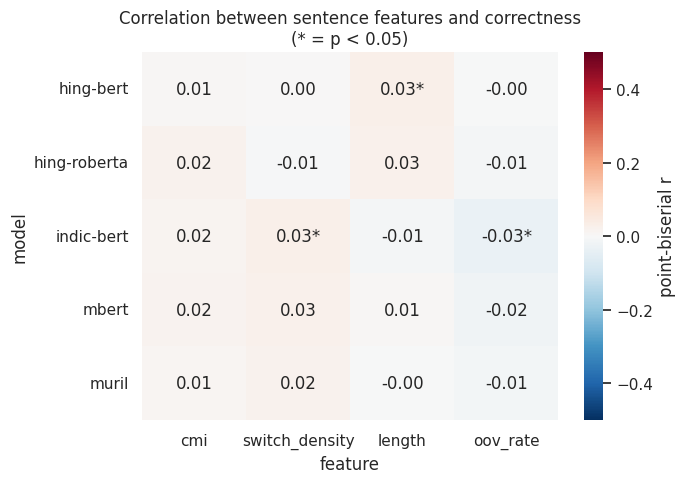

In [6]:
pivot_r = pointbiserial_df.pivot(index='model', columns='feature', values='r')[FEATURE_COLS]
pivot_p = pointbiserial_df.pivot(index='model', columns='feature', values='p_value')[FEATURE_COLS]

annot = pivot_r.copy().astype(object)
for m in pivot_r.index:
    for f in pivot_r.columns:
        star = '*' if pivot_p.loc[m, f] < 0.05 else ''
        annot.loc[m, f] = f"{pivot_r.loc[m, f]:.2f}{star}"

plt.figure(figsize=(7, 5))
sns.heatmap(pivot_r, annot=annot.values, fmt='', cmap='RdBu_r', center=0, vmin=-0.5, vmax=0.5,
            cbar_kws={'label': 'point-biserial r'})
plt.title('Correlation between sentence features and correctness\n(* = p < 0.05)')
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'pointbiserial_heatmap.png'), dpi=150)
plt.show()

## Analysis 2 — Accuracy by CMI bucket (headline table)

**Do not use `pd.qcut`** — the corpus has a large mass of monolingual tweets at
`cmi == 0`, which collapses tertiles and crashes `qcut`. Explicit thresholds instead,
with the median computed on the **test set only**:

```
low  : cmi == 0
mid  : 0 < cmi <= median_cmi_of_test_set
high : cmi > median_cmi_of_test_set
```

**Bootstrap methodology (documented per spec):** resampling is done at the **sentence
level, pooled across seeds** — a *block* bootstrap. Each of the 2000 iterations resamples
unique `sentence_id`s with replacement and pulls in all 3 seed-predictions for each
resampled sentence. This is deliberately different from resampling all `3 x n` rows
independently, which would treat the 3 correlated seed-predictions of the same sentence
as independent draws and understate the CI width.

The **robustness gap** = `accuracy(low) - accuracy(high)` per model is the headline
number: the hypothesis is that Hinglish-specific models (HingBERT, HingRoBERTa) show a
*smaller* gap than general models (mBERT, MuRIL, IndicBERT). A null result here is still
reportable as long as it comes with the CI.

In [7]:
# Calculate the 33rd and 67th percentiles on the unique test sentences
unique_test_cmi = df.drop_duplicates('sentence_id')['cmi']
p33 = unique_test_cmi.quantile(0.3333)
p67 = unique_test_cmi.quantile(0.6667)

print(f"CMI Tertiles (test set) -> 33rd: {p33:.4f}, 67th: {p67:.4f}")

def assign_bucket(cmi):
    if cmi <= p33:
        return 'low'
    elif cmi <= p67:
        return 'mid'
    else:
        return 'high'

df['cmi_bucket'] = df['cmi'].apply(assign_bucket)
bucket_order = ['low', 'mid', 'high']

bucket_sizes = (df.drop_duplicates('sentence_id')
                  .groupby('cmi_bucket')['sentence_id'].count()
                  .reindex(bucket_order))

print("Bucket sizes (unique test sentences):")
print(bucket_sizes)

CMI Tertiles (test set) -> 33rd: 23.0800, 67th: 35.0000
Bucket sizes (unique test sentences):
cmi_bucket
low     510
mid     503
high    501
Name: sentence_id, dtype: int64


In [8]:
def block_bootstrap_accuracy(sub_df, n_boot=N_BOOTSTRAP, rng=rng):
    # Bootstrap CI for mean accuracy, resampling sentence_ids with replacement
    # (block bootstrap: all seed-rows for a resampled sentence travel together).
    mat = sub_df.pivot_table(index='sentence_id', columns='seed', values='correct').values
    n_sent = mat.shape[0]
    if n_sent == 0:
        raise ValueError(
            "block_bootstrap_accuracy got an empty group (0 sentences) -- check "
            "that every model has predictions covering every cmi_bucket."
        )
    point_est = np.nanmean(mat)

    idx = rng.integers(0, n_sent, size=(n_boot, n_sent))
    boot_accs = np.nanmean(mat[idx].reshape(n_boot, -1), axis=1)

    ci_lo, ci_hi = np.percentile(boot_accs, [2.5, 97.5])
    return point_est, ci_lo, ci_hi

In [9]:
def cached_or_compute(cache_path, compute_fn, force=False):
    # Skip-if-exists wrapper for expensive cells (bootstrap, regression).
    if os.path.exists(cache_path) and not force:
        print(f"Loading cached result from {cache_path}")
        return pd.read_csv(cache_path)
    result = compute_fn()
    result.to_csv(cache_path, index=False)
    return result

In [10]:
def compute_bucket_stats():
    rows = []
    for model in MODEL_NAMES:
        for bucket in bucket_order:
            sub = df[(df['model'] == model) & (df['cmi_bucket'] == bucket)]
            if len(sub) == 0:
                continue
            point_est, ci_lo, ci_hi = block_bootstrap_accuracy(sub)
            rows.append({
                'model': model, 'bucket': bucket,
                'accuracy': point_est, 'ci_low': ci_lo, 'ci_high': ci_hi,
                'n_rows': len(sub), 'n_sentences': sub['sentence_id'].nunique(),
            })
    return pd.DataFrame(rows)

bucket_stats_path = os.path.join(RESULTS_DIR, 'cmi_bucket_accuracy_bootstrap.csv')
bucket_stats = cached_or_compute(bucket_stats_path, compute_bucket_stats)
bucket_stats

Loading cached result from /content/drive/MyDrive/codemix_project/results/cmi_bucket_accuracy_bootstrap.csv


,model,bucket,accuracy,ci_low,ci_high,n_rows,n_sentences
0,hing-bert,low,0.688235,0.652271,0.724199,1530,510
1,hing-bert,mid,0.687873,0.652087,0.723658,1509,503
2,hing-bert,high,0.687957,0.652029,0.724551,1503,501
3,hing-roberta,low,0.699346,0.662075,0.735294,1530,510
4,hing-roberta,mid,0.679920,0.643472,0.717031,1509,503
5,hing-roberta,high,0.703925,0.667332,0.739854,1503,501
6,indic-bert,low,0.623529,0.582337,0.662108,1530,510
7,indic-bert,mid,0.597747,0.558648,0.638834,1509,503
8,indic-bert,high,0.648037,0.610113,0.685296,1503,501
9,mbert,low,0.624837,0.588219,0.662092,1530,510


In [11]:
def compute_robustness_gap():
    rows = []
    for model in MODEL_NAMES:
        low_mat = df[(df['model'] == model) & (df['cmi_bucket'] == 'low')].pivot_table(
            index='sentence_id', columns='seed', values='correct').values
        high_mat = df[(df['model'] == model) & (df['cmi_bucket'] == 'high')].pivot_table(
            index='sentence_id', columns='seed', values='correct').values

        n_low, n_high = low_mat.shape[0], high_mat.shape[0]
        if n_low == 0 or n_high == 0:
            raise ValueError(
                f"compute_robustness_gap: model '{model}' has {n_low} low-bucket and "
                f"{n_high} high-bucket sentences -- can't compute a gap with an empty bucket."
            )

        gap_point = np.nanmean(low_mat) - np.nanmean(high_mat)

        idx_low = rng.integers(0, n_low, size=(N_BOOTSTRAP, n_low))
        idx_high = rng.integers(0, n_high, size=(N_BOOTSTRAP, n_high))
        boot_low = np.nanmean(low_mat[idx_low].reshape(N_BOOTSTRAP, -1), axis=1)
        boot_high = np.nanmean(high_mat[idx_high].reshape(N_BOOTSTRAP, -1), axis=1)
        boot_gap = boot_low - boot_high

        ci_lo, ci_hi = np.percentile(boot_gap, [2.5, 97.5])
        rows.append({
            'model': model,
            'robustness_gap': gap_point,
            'gap_ci_low': ci_lo,
            'gap_ci_high': ci_hi,
            'model_type': 'Hinglish-specific' if is_hinglish_specific(model) else 'general',
        })
    return pd.DataFrame(rows)

gap_path = os.path.join(RESULTS_DIR, 'robustness_gap.csv')
gap_stats = cached_or_compute(gap_path, compute_robustness_gap)
gap_stats.sort_values('robustness_gap', ascending=False)

Loading cached result from /content/drive/MyDrive/codemix_project/results/robustness_gap.csv


,model,robustness_gap,gap_ci_low,gap_ci_high,model_type
0,hing-bert,0.000278,-0.051674,0.053937,Hinglish-specific
4,muril,-0.004505,-0.057846,0.045700,general
1,hing-roberta,-0.004579,-0.054373,0.044388,Hinglish-specific
3,mbert,-0.015882,-0.070185,0.037949,general
2,indic-bert,-0.024508,-0.077459,0.031664,general


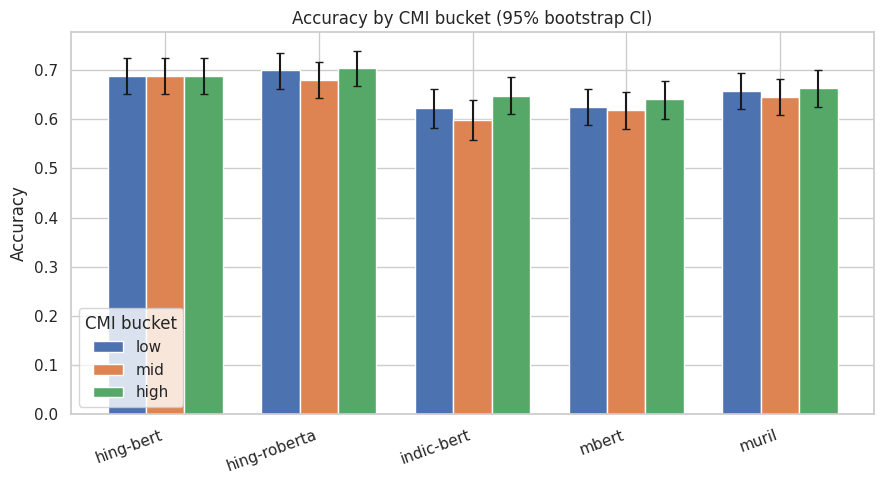

In [12]:
plt.figure(figsize=(9, 5))
x = np.arange(len(MODEL_NAMES))
width = 0.25
colors = {'low': '#4C72B0', 'mid': '#DD8452', 'high': '#55A868'}

for i, bucket in enumerate(bucket_order):
    b = bucket_stats[bucket_stats['bucket'] == bucket].set_index('model').reindex(MODEL_NAMES)
    errs = np.vstack([b['accuracy'] - b['ci_low'], b['ci_high'] - b['accuracy']])
    plt.bar(x + (i - 1) * width, b['accuracy'], width, yerr=errs, capsize=3,
            label=bucket, color=colors[bucket])

plt.xticks(x, MODEL_NAMES, rotation=20, ha='right')
plt.ylabel('Accuracy')
plt.title('Accuracy by CMI bucket (95% bootstrap CI)')
plt.legend(title='CMI bucket')
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'accuracy_by_cmi_bucket.png'), dpi=150)
plt.show()

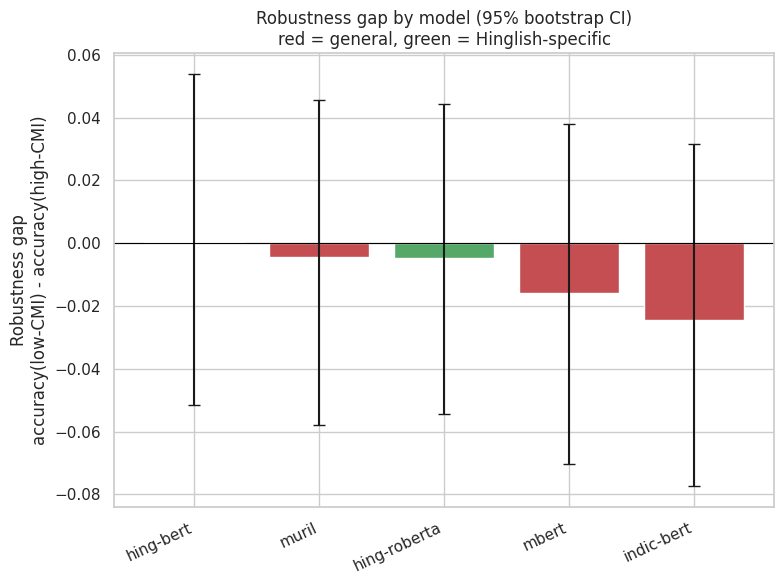

In [13]:
gap_sorted = gap_stats.sort_values('robustness_gap', ascending=False).reset_index(drop=True)
fig, ax = plt.subplots(figsize=(8, 6))
colors_gap = ['#C44E52' if t == 'general' else '#55A868' for t in gap_sorted['model_type']]
yerr = np.vstack([
    gap_sorted['robustness_gap'] - gap_sorted['gap_ci_low'],
    gap_sorted['gap_ci_high'] - gap_sorted['robustness_gap'],
])
ax.bar(gap_sorted['model'], gap_sorted['robustness_gap'], yerr=yerr, capsize=4, color=colors_gap)
ax.axhline(0, color='black', linewidth=0.8)
ax.set_ylabel('Robustness gap\naccuracy(low-CMI) - accuracy(high-CMI)')
ax.set_title('Robustness gap by model (95% bootstrap CI)\nred = general, green = Hinglish-specific')
ax.set_xticks(range(len(gap_sorted)))
ax.set_xticklabels(gap_sorted['model'], rotation=25, ha='right')
fig.tight_layout()
fig.savefig(os.path.join(FIGURES_DIR, 'robustness_gap.png'), dpi=150)
plt.show()

## Analysis 3 — Logistic regression

`correct ~ cmi + switch_density + length + oov_rate`, fit **per model**, pooling the 3
seeds' `3 x n_test` rows as independent observations. (Spec allows adding `seed` as a
fixed-effect dummy for a more conservative fit — that's noted as an option below rather
than done by default; the headline fit treats seed-pooling as independent draws.)

Before fitting:
1. **Collinearity check** — VIF on the four standardized predictors, flagging VIF > 5.
   If `oov_rate` is flagged, it's dropped (known confound with `hi_ratio` by
   construction, per `feature_spec.json`) — `hi_ratio` is **not** substituted in without
   its own VIF check.
2. **Standardization** — mean/std computed on the **train split** of `sa_master.parquet`
   (via `sentence_features.csv`, not the test set), then applied to the test-set rows
   used for fitting.

In [ ]:

train_ids = set(master.loc[master['split'] == 'train', 'sentence_id'].astype(str))
feats_all = pd.read_csv(feat_path)
feats_all['sentence_id'] = feats_all['sentence_id'].astype(str)
train_feats = feats_all[feats_all['sentence_id'].isin(train_ids)]

scaler_stats = {c: (train_feats[c].mean(), train_feats[c].std(ddof=0)) for c in FEATURE_COLS}

print("Standardization stats (from train split):")
vif_z_cols = []
for c in FEATURE_COLS:
    m, s = scaler_stats[c]
    print(f"  {c}: mean={m:.4f}, std={s:.4f}")
    if s == 0 or pd.isna(s):
        print(f"  -> '{c}' has zero variance on the train split -- not standardizing or "
              f"including it. This should not happen once Phase 3 is correct; treat it as "
              f"a signal to go check Phase 3, not just accept the drop.")
        continue
    df[f'{c}_z'] = (df[c] - m) / s
    vif_z_cols.append(f'{c}_z')

def compute_vif(sub_df, cols):
    X = sm.add_constant(sub_df[cols])
    vifs = pd.Series(
        [variance_inflation_factor(X.values, i) for i in range(X.shape[1])],
        index=X.columns,
    )
    return vifs.drop('const')

vif_overall = compute_vif(df, vif_z_cols)
print("\nVIF (pooled test rows, standardized predictors):")
print(vif_overall)

high_vif = vif_overall[vif_overall > 5]
predictors_to_use = list(vif_z_cols)
if len(high_vif):
    print(f"\nHigh VIF flagged: {dict(high_vif)}")
    if 'oov_rate_z' in high_vif.index:
        predictors_to_use.remove('oov_rate_z')
        print("Dropping oov_rate_z due to collinearity (correlates with hi_ratio by "
              "construction, per feature_spec.json). Not substituting hi_ratio without "
              "checking its own VIF.")
else:
    print("\nNo predictor exceeds VIF > 5; keeping all available predictors.")

print("\nPredictors used in the fit:", predictors_to_use)

Standardization stats (from train split):
  cmi: mean=29.7554, std=10.3035
  switch_density: mean=0.1858, std=0.0971
  length: mean=26.1671, std=6.3462
  oov_rate: mean=0.4186, std=0.1805

VIF (pooled test rows, standardized predictors):
cmi_z               1.369855
switch_density_z    1.283433
length_z            1.225648
oov_rate_z          1.021307
dtype: float64

No predictor exceeds VIF > 5; keeping all available predictors.

Predictors used in the fit: ['cmi_z', 'switch_density_z', 'length_z', 'oov_rate_z']


In [15]:
def compute_logit_results():
    rows = []
    calib_rows = []
    formula_rhs = ' + '.join(predictors_to_use)
    for model in MODEL_NAMES:
        sub = df[df['model'] == model].copy()
        res = smf.logit(f'correct ~ {formula_rhs}', data=sub).fit(disp=0)

        conf = res.conf_int()
        conf.columns = ['ci_low', 'ci_high']
        for term in res.params.index:
            coef = res.params[term]
            rows.append({
                'model': model,
                'term': term,
                'coef': coef,
                'std_err': res.bse[term],
                'ci_low': conf.loc[term, 'ci_low'],
                'ci_high': conf.loc[term, 'ci_high'],
                'p_value': res.pvalues[term],
                'odds_ratio': np.exp(coef),
                'or_ci_low': np.exp(conf.loc[term, 'ci_low']),
                'or_ci_high': np.exp(conf.loc[term, 'ci_high']),
                'pseudo_r2_mcfadden': res.prsquared,
                'n_obs': int(res.nobs),
            })

        # calibration: predicted probability vs observed accuracy, by decile
        sub['pred_prob'] = res.predict(sub)
        sub['decile'] = pd.qcut(sub['pred_prob'], 10, duplicates='drop')
        calib = sub.groupby('decile', observed=True).agg(
            mean_pred_prob=('pred_prob', 'mean'),
            observed_accuracy=('correct', 'mean'),
            n=('correct', 'size'),
        ).reset_index(drop=True)
        calib['model'] = model
        calib_rows.append(calib)

    coef_df = pd.DataFrame(rows)
    calib_df = pd.concat(calib_rows, ignore_index=True)
    return coef_df, calib_df

logit_path = os.path.join(RESULTS_DIR, 'logit_coefficients.csv')
calib_path = os.path.join(RESULTS_DIR, 'logit_calibration.csv')

if os.path.exists(logit_path) and os.path.exists(calib_path):
    print("Loading cached logistic regression results.")
    logit_coefficients = pd.read_csv(logit_path)
    calibration_df = pd.read_csv(calib_path)
else:
    logit_coefficients, calibration_df = compute_logit_results()
    logit_coefficients.to_csv(logit_path, index=False)
    calibration_df.to_csv(calib_path, index=False)

logit_coefficients

Loading cached logistic regression results.


,model,term,coef,std_err,ci_low,ci_high,p_value,odds_ratio,or_ci_low,or_ci_high,pseudo_r2_mcfadden,n_obs
0,hing-bert,Intercept,0.792927,0.032088,0.730034,0.855819,8.220161e-135,2.209854,2.075152,2.353301,0.001070,4542
1,hing-bert,cmi_z,0.041488,0.037681,-0.032365,0.115341,2.708828e-01,1.042361,0.968153,1.122256,0.001070,4542
2,hing-bert,switch_density_z,0.015045,0.035961,-0.055438,0.085527,6.756821e-01,1.015159,0.946071,1.089291,0.001070,4542
3,hing-bert,length_z,0.086965,0.035967,0.016472,0.157458,1.560896e-02,1.090858,1.016608,1.170532,0.001070,4542
4,hing-bert,oov_rate_z,0.001271,0.031327,-0.060130,0.062671,9.676484e-01,1.001271,0.941642,1.064676,0.001070,4542
5,hing-roberta,Intercept,0.822940,0.032286,0.759661,0.886220,2.602402e-143,2.277186,2.137552,2.425941,0.001613,4542
6,hing-roberta,cmi_z,0.090582,0.038081,0.015945,0.165220,1.737498e-02,1.094812,1.016073,1.179652,0.001613,4542
7,hing-roberta,switch_density_z,-0.029554,0.036129,-0.100366,0.041257,4.133462e-01,0.970878,0.904507,1.042120,0.001613,4542
8,hing-roberta,length_z,0.084340,0.036285,0.013222,0.155458,2.010590e-02,1.087999,1.013310,1.168193,0.001613,4542
9,hing-roberta,oov_rate_z,-0.017867,0.031476,-0.079560,0.043826,5.702914e-01,0.982292,0.923523,1.044801,0.001613,4542


In [16]:
print("Calibration check (predicted probability vs observed accuracy, by decile):")
for model in MODEL_NAMES:
    m = calibration_df[calibration_df['model'] == model]
    max_gap = (m['mean_pred_prob'] - m['observed_accuracy']).abs().max()
    flag = "  <-- possible miscalibration (max gap > 0.10)" if max_gap > 0.1 else ""
    print(f"  {model}: max |predicted - observed| across deciles = {max_gap:.3f}{flag}")

Calibration check (predicted probability vs observed accuracy, by decile):
  hing-bert: max |predicted - observed| across deciles = 0.088
  hing-roberta: max |predicted - observed| across deciles = 0.060
  indic-bert: max |predicted - observed| across deciles = 0.052
  mbert: max |predicted - observed| across deciles = 0.077
  muril: max |predicted - observed| across deciles = 0.039


In [17]:
print("Effect direction / size summary (standardized predictors; positive coef = feature "
      "increases odds of a correct prediction):")
sig = logit_coefficients[
    (logit_coefficients['term'] != 'Intercept') & (logit_coefficients['p_value'] < 0.05)
]
if len(sig) == 0:
    print("  No predictor reached p < 0.05 for any model.")
for _, row in sig.iterrows():
    direction = 'increases' if row['coef'] > 0 else 'decreases'
    print(f"  [{row['model']}] {row['term']}: {direction} odds of correctness "
          f"(OR={row['odds_ratio']:.3f}, 95% CI [{row['or_ci_low']:.3f}, {row['or_ci_high']:.3f}], "
          f"p={row['p_value']:.4f})")

print("\nMcFadden pseudo-R^2 by model:")
print(logit_coefficients.drop_duplicates('model')[['model', 'pseudo_r2_mcfadden']]
      .to_string(index=False))

Effect direction / size summary (standardized predictors; positive coef = feature increases odds of a correct prediction):
  [hing-bert] length_z: increases odds of correctness (OR=1.091, 95% CI [1.017, 1.171], p=0.0156)
  [hing-roberta] cmi_z: increases odds of correctness (OR=1.095, 95% CI [1.016, 1.180], p=0.0174)
  [hing-roberta] length_z: increases odds of correctness (OR=1.088, 95% CI [1.013, 1.168], p=0.0201)
  [indic-bert] oov_rate_z: decreases odds of correctness (OR=0.937, 95% CI [0.883, 0.994], p=0.0309)

McFadden pseudo-R^2 by model:
       model  pseudo_r2_mcfadden
   hing-bert            0.001070
hing-roberta            0.001613
  indic-bert            0.001491
       mbert            0.000994
       muril            0.000509


## Analysis 4 — McNemar's test (pairwise model comparison)

10 pairs from 5 models. Uses the **modal prediction** per sentence per model (majority
vote of `pred_label` over the 3 seeds) to get one binary "correct" per (model,
sentence_id), then `statsmodels`' McNemar test (`exact=False`, continuity-corrected — n
is large enough for the chi-squared approximation), with Holm-Bonferroni correction
across the 10 p-values.

In [18]:
def modal_correct(sub):
    modal_pred = sub.groupby('sentence_id')['pred_label'].agg(
        lambda x: x.value_counts().idxmax()
    )
    true_label = sub.groupby('sentence_id')['true_label'].first()
    return (modal_pred == true_label).astype(int)

modal_by_model = {}
for model in MODEL_NAMES:
    modal_by_model[model] = modal_correct(df[df['model'] == model])

modal_matrix = pd.DataFrame(modal_by_model)
assert modal_matrix.isna().sum().sum() == 0, "Missing modal predictions for some sentence_id."
print(f"Modal prediction matrix shape: {modal_matrix.shape}")

Modal prediction matrix shape: (1514, 5)


In [19]:
pairs = list(combinations(MODEL_NAMES, 2))
mc_rows = []
for m1, m2 in pairs:
    both_correct = int(((modal_matrix[m1] == 1) & (modal_matrix[m2] == 1)).sum())
    m1_only      = int(((modal_matrix[m1] == 1) & (modal_matrix[m2] == 0)).sum())
    m2_only      = int(((modal_matrix[m1] == 0) & (modal_matrix[m2] == 1)).sum())
    both_wrong   = int(((modal_matrix[m1] == 0) & (modal_matrix[m2] == 0)).sum())

    table = [[both_correct, m1_only], [m2_only, both_wrong]]
    result = mcnemar(table, exact=False, correction=True)

    mc_rows.append({
        'model_a': m1, 'model_b': m2,
        'both_correct': both_correct, 'a_only_correct': m1_only,
        'b_only_correct': m2_only, 'both_wrong': both_wrong,
        'statistic': result.statistic, 'p_value_raw': result.pvalue,
    })

mcnemar_df = pd.DataFrame(mc_rows)
reject, p_corrected, _, _ = multipletests(mcnemar_df['p_value_raw'], alpha=0.05, method='holm')
mcnemar_df['p_value_holm'] = p_corrected
mcnemar_df['significant_holm'] = reject

def interpret(row):
    if not row['significant_holm']:
        return (f"No significant difference between {row['model_a']} and {row['model_b']} "
                f"after Holm correction.")
    winner = row['model_a'] if row['a_only_correct'] > row['b_only_correct'] else row['model_b']
    return (f"{winner} significantly outperforms the other on discordant sentences "
            f"(Holm-corrected p={row['p_value_holm']:.4f}).")

mcnemar_df['interpretation'] = mcnemar_df.apply(interpret, axis=1)
mcnemar_df.to_csv(os.path.join(RESULTS_DIR, 'mcnemar_pairs.csv'), index=False)
mcnemar_df

,model_a,model_b,both_correct,a_only_correct,b_only_correct,both_wrong,statistic,p_value_raw,p_value_holm,significant_holm,interpretation
0,hing-bert,hing-roberta,963,91,98,362,0.190476,6.625206e-01,1.000000e+00,False,No significant difference between hing-bert an...
1,hing-bert,indic-bert,824,230,137,323,23.062670,1.568057e-06,1.097640e-05,True,hing-bert significantly outperforms the other ...
2,hing-bert,mbert,835,219,125,335,25.142442,5.324794e-07,4.259835e-06,True,hing-bert significantly outperforms the other ...
3,hing-bert,muril,896,158,104,356,10.721374,1.059050e-03,5.295250e-03,True,hing-bert significantly outperforms the other ...
4,hing-roberta,indic-bert,845,216,116,337,29.521084,5.531171e-08,4.978054e-07,True,hing-roberta significantly outperforms the oth...
5,hing-roberta,mbert,853,208,107,346,31.746032,1.757079e-08,1.757079e-07,True,hing-roberta significantly outperforms the oth...
6,hing-roberta,muril,900,161,100,353,13.793103,2.040840e-04,1.224504e-03,True,hing-roberta significantly outperforms the oth...
7,indic-bert,mbert,814,147,146,407,0.000000,1.000000e+00,1.000000e+00,False,No significant difference between indic-bert a...
8,indic-bert,muril,823,138,177,376,4.584127,3.226941e-02,9.680822e-02,False,No significant difference between indic-bert a...
9,mbert,muril,836,124,164,390,5.281250,2.155627e-02,8.622507e-02,False,No significant difference between mbert and mu...


## Reporting outputs



In [20]:
summary_rows = []
for model in MODEL_NAMES:
    sub = df[df['model'] == model]
    row = {
        'model': model,
        'model_type': 'Hinglish-specific' if is_hinglish_specific(model) else 'general',
        'overall_accuracy': sub['correct'].mean(),
        'n_rows': len(sub),
        'n_sentences': sub['sentence_id'].nunique(),
    }
    for bucket in bucket_order:
        b = bucket_stats[(bucket_stats['model'] == model) & (bucket_stats['bucket'] == bucket)]
        if len(b):
            row[f'acc_{bucket}'] = b['accuracy'].values[0]
            row[f'acc_{bucket}_ci_low'] = b['ci_low'].values[0]
            row[f'acc_{bucket}_ci_high'] = b['ci_high'].values[0]
            row[f'n_{bucket}'] = b['n_sentences'].values[0]
    gap_row = gap_stats[gap_stats['model'] == model]
    row['robustness_gap'] = gap_row['robustness_gap'].values[0]
    row['robustness_gap_ci_low'] = gap_row['gap_ci_low'].values[0]
    row['robustness_gap_ci_high'] = gap_row['gap_ci_high'].values[0]
    summary_rows.append(row)

phase4_summary = pd.DataFrame(summary_rows)
phase4_summary.to_csv(os.path.join(RESULTS_DIR, 'phase4_analysis.csv'), index=False)
phase4_summary

,model,model_type,overall_accuracy,n_rows,n_sentences,acc_low,acc_low_ci_low,acc_low_ci_high,n_low,acc_mid,acc_mid_ci_low,acc_mid_ci_high,n_mid,acc_high,acc_high_ci_low,acc_high_ci_high,n_high,robustness_gap,robustness_gap_ci_low,robustness_gap_ci_high
0,hing-bert,Hinglish-specific,0.688023,4542,1514,0.688235,0.652271,0.724199,510,0.687873,0.652087,0.723658,503,0.687957,0.652029,0.724551,501,0.000278,-0.051674,0.053937
1,hing-roberta,Hinglish-specific,0.694408,4542,1514,0.699346,0.662075,0.735294,510,0.679920,0.643472,0.717031,503,0.703925,0.667332,0.739854,501,-0.004579,-0.054373,0.044388
2,indic-bert,general,0.623074,4542,1514,0.623529,0.582337,0.662108,510,0.597747,0.558648,0.638834,503,0.648037,0.610113,0.685296,501,-0.024508,-0.077459,0.031664
3,mbert,general,0.627917,4542,1514,0.624837,0.588219,0.662092,510,0.618290,0.580517,0.656064,503,0.640719,0.601464,0.677977,501,-0.015882,-0.070185,0.037949
4,muril,general,0.655218,4542,1514,0.658170,0.620261,0.694134,510,0.644798,0.607687,0.681925,503,0.662675,0.624085,0.700615,501,-0.004505,-0.057846,0.045700


In [21]:
general_gap = phase4_summary.loc[phase4_summary['model_type'] == 'general', 'robustness_gap'].mean()
hinglish_gap = phase4_summary.loc[phase4_summary['model_type'] == 'Hinglish-specific', 'robustness_gap'].mean()

print(f"Mean robustness gap -- general models:            {general_gap:.4f}")
print(f"Mean robustness gap -- Hinglish-specific models:   {hinglish_gap:.4f}")
print(f"Hypothesis (Hinglish-specific gap < general gap) supported: {hinglish_gap < general_gap}")
print()
print("Per-model gaps with bootstrap CI:")
print(gap_stats.sort_values('robustness_gap', ascending=False).to_string(index=False))

Mean robustness gap -- general models:            -0.0150
Mean robustness gap -- Hinglish-specific models:   -0.0022
Hypothesis (Hinglish-specific gap < general gap) supported: False

Per-model gaps with bootstrap CI:
       model  robustness_gap  gap_ci_low  gap_ci_high        model_type
   hing-bert        0.000278   -0.051674     0.053937 Hinglish-specific
       muril       -0.004505   -0.057846     0.045700           general
hing-roberta       -0.004579   -0.054373     0.044388 Hinglish-specific
       mbert       -0.015882   -0.070185     0.037949           general
  indic-bert       -0.024508   -0.077459     0.031664           general


## Outputs written this notebook

| File | Content |
|---|---|
| `results/phase4_analysis.csv` | per-model accuracy, CMI-bucket accuracies, robustness gap, bootstrap CIs |
| `results/pointbiserial_correlations.csv` | r, CI, p per model x feature |
| `results/cmi_bucket_accuracy_bootstrap.csv` | accuracy + bootstrap CI per model x bucket |
| `results/robustness_gap.csv` | gap + bootstrap CI per model |
| `results/logit_coefficients.csv` | coef, SE, CI, p, OR, pseudo-R^2 per model x predictor |
| `results/logit_calibration.csv` | predicted-probability-decile calibration table per model |
| `results/mcnemar_pairs.csv` | contingency table, Holm-corrected p, interpretation per pair |
| `figures/pointbiserial_heatmap.png` | r per model x feature, annotated with significance |
| `figures/accuracy_by_cmi_bucket.png` | grouped bar chart, bootstrap error bars |
| `figures/robustness_gap.png` | gap per model, sorted, with CI bars |



In [22]:
!pip freeze | grep -iE "^(transformers|torch|datasets|accelerate|scikit-learn|scipy|statsmodels|pandas|numpy|pyarrow|wordfreq|matplotlib|seaborn|sentencepiece)=="

accelerate==1.15.0
datasets==4.8.5
matplotlib==3.10.0
numpy==2.1.3
pandas==2.2.3
pyarrow==23.0.1
scikit-learn==1.6.1
scipy==1.16.3
seaborn==0.13.2
sentencepiece==0.2.2
statsmodels==0.15.0
torch==2.11.0+cu130
transformers==5.18.0
